<a href="https://colab.research.google.com/github/1824034QM/1824034QM/blob/main/Unit1(b).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

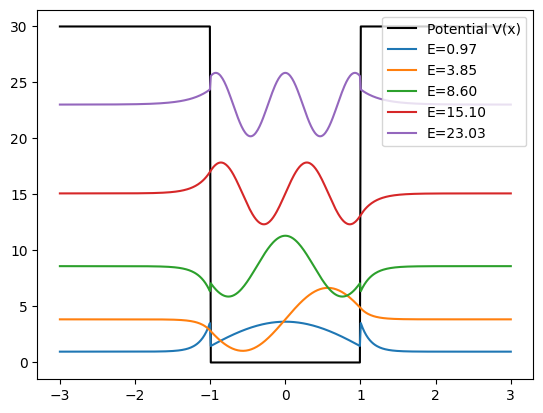

In [2]:


import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.integrate import trapezoid

# well parameters (hbar=1, m=1)
V0, a = 30, 1

def k(E):
    return np.sqrt(2*E)

def alpha(E):
    return np.sqrt(2*(V0-E))

# transcendental equations
def even(E):
    return alpha(E)*np.cos(k(E)*a) - k(E)*np.sin(k(E)*a)

def odd(E):
    return alpha(E)*np.sin(k(E)*a) + k(E)*np.cos(k(E)*a)

# energy eigenvalues
E_scan = np.linspace(0.1, V0-0.1, 1000)
energies = []

for func, parity in [(even, 'even'), (odd, 'odd')]:
    crossings = np.where(np.diff(np.sign(func(E_scan))))[0]

    for i in crossings:
        root = brentq(func, E_scan[i], E_scan[i+1])
        energies.append((root, parity))

energies.sort()

x = np.linspace(-3*a, 3*a, 500)

plt.plot(x, np.where((x >= -a) & (x <= a), 0, V0),
         'k-', label='Potential V(x)')

for E, parity in energies:
    psi = np.zeros_like(x)

    inside = (x >= -a) & (x <= a)
    right, left = (x > a), (x < -a)

    if parity == 'even':
        psi[inside] = np.cos(k(E)*x[inside])
        C = np.sin(k(E)*a)*np.exp(alpha(E)*a)
        psi[right] = C*np.exp(-alpha(E)*x[right])
        psi[left] = C*np.exp(alpha(E)*x[left])

    else:
        psi[inside] = np.sin(k(E)*x[inside])
        C = np.sin(k(E)*a)*np.exp(alpha(E)*a)
        psi[right] = C*np.exp(-alpha(E)*x[right])
        psi[left] = -C*np.exp(alpha(E)*x[left])

    # normalize
    psi /= np.sqrt(trapezoid(psi**2, x))

    plt.plot(x, E+3*psi, label=f'E={E:.2f}')

plt.legend(loc='upper right')
plt.show()